In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import matplotlib as mpl

RT, OF, TRUE = '#2a78d6', '#eb6834', '#1baf7a'      # realtime / offline / truth
INK, MUTED, SURFACE, GRID = '#0b0b0b', '#52514e', '#fcfcfb', '#e6e5e2'

def tidy(ax, grid='y'):
    ax.set_facecolor(SURFACE)
    if grid: ax.grid(axis=grid, lw=.6, color=GRID, zorder=0)
    ax.set_axisbelow(True)
    for s in ('top', 'right'):   ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color('#d9d8d4')
    ax.tick_params(colors=MUTED, labelsize=9)
    return ax

In [13]:
decoder_output_dir = '/media/ssd1/decoder_output'
animal = 'Toby'
date = '20250316'
session__id = '07'
epoch = 'r4_merged_random_no_preload'

In [16]:
realtime_results_file = f'/media/ssd1/decoder_output_merged/{animal}/{animal}_{date}_{session__id}_{epoch}_decoded_merged_uniform_transmat.pkl'
offline_results_file = f'{decoder_output_dir}/{animal}/{date}_{session__id}_{epoch}/{animal}{date}_epoch{session__id[1]}_combined.pkl'

In [17]:
realtime_results_df = pd.read_pickle(realtime_results_file)
offline_results_df = pd.read_pickle(offline_results_file)

In [41]:
display(offline_results_df)

,position_x,position_y,orientation,velocity_x,velocity_y,speed,hex,hex_including_sides,distance_from_centroid,in_maze,...,decode_hex_any,decode_hex_any_including_sides,decode_any_distance_from_centroid,decode_hex_blocks_since_open,decode_hex_open_status,decode_in_maze,decode_distance,decode_hex_distance,hpd_thresh,spatial_cov
time,,,,,,,,,,,,,,,,,,,,,
1.742172e+09,62.041250,103.872500,-0.366782,38.442561,-29.824666,48.655331,44,44,2.774555,1,...,44,44,9.600141,0,open,0,-7.729128,0,0.000315,1262
1.742172e+09,62.210588,103.720000,-0.365368,38.766769,-29.891796,48.952853,44,44,2.548839,1,...,44,44,8.229055,0,open,1,-6.041434,0,0.000329,1277
1.742172e+09,62.301176,103.640000,-0.363602,39.087138,-29.952861,49.244068,44,44,2.429481,1,...,44,44,8.229055,0,open,1,-6.148604,0,0.000251,1231
1.742172e+09,62.391765,103.560000,-0.361809,39.403551,-30.007786,49.528851,44,44,2.310278,1,...,44,44,8.229055,0,open,1,-6.256274,0,0.000335,1292
1.742172e+09,62.482353,103.480000,-0.360012,39.715893,-30.056504,49.807083,44,44,2.191257,1,...,44,44,8.229055,0,open,1,-6.364417,0,0.000319,1293
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1.742175e+09,76.652941,124.638824,2.242746,-19.005807,23.497184,30.221488,-100,None,-100.000000,1,...,21,21,5.771579,-100,None,1,-44.896417,-100,0.000170,976
1.742175e+09,76.608235,124.684706,2.245406,-18.953989,23.338596,30.065657,-100,None,-100.000000,1,...,21,21,5.771579,-100,None,1,-44.959833,-100,0.000156,1079
1.742175e+09,76.563529,124.730588,2.248083,-18.900738,23.180486,29.909410,-100,None,-100.000000,1,...,21,21,3.814919,-100,None,1,-46.619909,-100,0.000166,1131


In [18]:
display(realtime_results_df.head().keys())
display(offline_results_df.head().keys())

Index(['trodes_sample', 'bin_timestamp_r', 'trigger_sample', 'playback_time',
       'dec_rank', 'spike_count', 'decoded_hex', 'posterior_max',
       'likelihood_hex', 'likelihood_max',
       ...
       'lik_hex40', 'lik_hex41', 'lik_hex42', 'lik_hex43', 'lik_hex44',
       'lik_hex45', 'lik_hex46', 'lik_hex47', 'lik_hex48', 'lik_hex49'],
      dtype='str', length=120)

Index(['position_x', 'position_y', 'orientation', 'velocity_x', 'velocity_y',
       'speed', 'hex', 'hex_including_sides', 'distance_from_centroid',
       'in_maze', 'decode_position_x', 'decode_position_y', 'decode_hex',
       'decode_hex_including_sides', 'decode_distance_from_centroid',
       'decode_hex_epoch_open', 'decode_hex_epoch_open_including_sides',
       'decode_epoch_open_distance_from_centroid', 'decode_hex_any',
       'decode_hex_any_including_sides', 'decode_any_distance_from_centroid',
       'decode_hex_blocks_since_open', 'decode_hex_open_status',
       'decode_in_maze', 'decode_distance', 'decode_hex_distance',
       'hpd_thresh', 'spatial_cov'],
      dtype='object')

## 1 · Time-bin alignment

Both frames are already indexed by **unix seconds of the original recording**, so they are
directly comparable without a conversion:

| frame | index | derived from |
|---|---|---|
| `realtime_results_df` | `recording_unix` | `trodes_sample` anchored to the `.rec` header (see `content_analysis/README.md`) |
| `offline_results_df` | `time` | the non_local_detector decode time index |

Two questions here: (a) do they cover the same stretch of the epoch, and (b) how many realtime
bins have no offline bin within 5 ms.

In [19]:
LOCAL_TZ = 'US/Pacific'
TOL = 0.002          # 5 ms "corresponding bin" tolerance

t_rt  = realtime_results_df.index.to_numpy(float)
t_off = offline_results_df.index.to_numpy(float)

def bin_summary(name, t):
    d = np.diff(t)
    med = np.median(d)
    return pd.Series({
        'n_bins'       : len(t),
        'start_local'  : pd.to_datetime(t[0],  unit='s', utc=True).tz_convert(LOCAL_TZ),
        'end_local'    : pd.to_datetime(t[-1], unit='s', utc=True).tz_convert(LOCAL_TZ),
        'first_unix'   : t[0],
        'last_unix'    : t[-1],
        'span_s'       : t[-1] - t[0],
        'median_dt_ms' : med * 1e3,
        'max_dt_ms'    : d.max() * 1e3,
        # a "gap" = a step more than 1.5x the nominal bin width, i.e. a dropped bin
        'n_gaps'       : int((d > 1.5 * med).sum()),
        'sorted'       : bool(np.all(d >= 0)),
        'n_duplicate_t': int(pd.Index(t).duplicated().sum()),
    }, name=name)

ranges = pd.concat([bin_summary('realtime', t_rt),
                    bin_summary('offline',  t_off)], axis=1)
display(ranges)

lo, hi = max(t_rt[0], t_off[0]), min(t_rt[-1], t_off[-1])
print(f"realtime starts {t_rt[0]-t_off[0]:+.4f} s relative to offline start")
print(f"realtime ends   {t_rt[-1]-t_off[-1]:+.4f} s relative to offline end")
print(f"overlap window  : {hi-lo:.3f} s "
      f"({100*(hi-lo)/max(t_rt[-1]-t_rt[0], t_off[-1]-t_off[0]):.2f}% of the longer record)")
print(f"realtime bins outside overlap: {(t_rt<lo).sum()} before, {(t_rt>hi).sum()} after")
print(f"offline  bins outside overlap: {(t_off<lo).sum()} before, {(t_off>hi).sum()} after")

,realtime,offline
n_bins,460380,1372600
start_local,2025-03-16 17:44:06.157766581-07:00,2025-03-16 17:44:20.023535252-07:00
end_local,2025-03-16 18:30:08.431766510-07:00,2025-03-16 18:30:05.220997572-07:00
first_unix,1742172246.157767,1742172260.023535
last_unix,1742175008.431767,1742175005.220998
span_s,2762.274,2745.197462
median_dt_ms,6.000042,2.000093
max_dt_ms,6.00028,2.000093
n_gaps,0,0
sorted,True,True


realtime starts -13.8658 s relative to offline start
realtime ends   +3.2108 s relative to offline end
overlap window  : 2745.197 s (99.38% of the longer record)
realtime bins outside overlap: 2311 before, 536 after
offline  bins outside overlap: 0 before, 0 after


### 1b · Nearest-neighbour match, realtime → offline

For every realtime bin, find the closest offline bin (checking the neighbour on each side of the
`searchsorted` insertion point) and look at the tolerance the match needs.

In [20]:
def nearest(t_query, t_ref):
    """For each t_query, the signed offset to the nearest t_ref and that reference's index."""
    i  = np.searchsorted(t_ref, t_query)
    lo_i, hi_i = np.clip(i-1, 0, len(t_ref)-1), np.clip(i, 0, len(t_ref)-1)
    d_lo, d_hi = t_query - t_ref[lo_i], t_query - t_ref[hi_i]
    take_lo = np.abs(d_lo) <= np.abs(d_hi)
    return np.where(take_lo, d_lo, d_hi), np.where(take_lo, lo_i, hi_i)

dt, match_idx = nearest(t_rt, t_off)
adt = np.abs(dt)

sweep = pd.DataFrame([
    {'tol_ms': tol,
     'matched': int((adt <= tol/1e3).sum()),
     'unmatched': int((adt > tol/1e3).sum()),
     'pct_matched': 100*(adt <= tol/1e3).mean()}
    for tol in [0, 0.5, 1, 2, 3, 5, 10, 50, 1000]
]).set_index('tol_ms')
display(sweep)

print("|dt| to nearest offline bin, ms:")
display(pd.Series(np.percentile(adt, [0,25,50,75,90,95,99,100])*1e3,
                  index=['min','p25','p50','p75','p90','p95','p99','max']).round(4))
print(f"mean signed dt (realtime - offline): {dt.mean()*1e3:+.4f} ms")

n_un = int((adt > TOL).sum())
print(f"\n>>> {n_un:,} of {len(t_rt):,} realtime bins ({100*n_un/len(t_rt):.4f}%) "
      f"have NO offline bin within {TOL*1e3:.0f} ms")

,matched,unmatched,pct_matched
tol_ms,,,
0.0,0,460380,0.000000
0.5,228736,231644,49.684174
1.0,457534,2846,99.381815
2.0,457534,2846,99.381815
3.0,457534,2846,99.381815
5.0,457534,2846,99.381815
10.0,457536,2844,99.382249
50.0,457550,2830,99.385290
1000.0,457866,2514,99.453929


|dt| to nearest offline bin, ms:


min        0.2310
p25        0.3664
p50        0.5019
p75        0.6371
p90        0.7181
p95        0.7453
p99        0.7670
max    13865.7687
dtype: float64

mean signed dt (realtime - offline): -32.4494 ms

>>> 2,846 of 460,380 realtime bins (0.6182%) have NO offline bin within 2 ms


### 1c · Where are the unmatched bins, and do the grids nest?

Unmatched bins grouped into contiguous runs — a handful of long runs means a coverage
difference at the edges, scattered singletons would mean genuinely dropped bins.

In [21]:
unmatched = adt > TOL
if unmatched.any():
    pos    = np.flatnonzero(unmatched)
    brk    = np.flatnonzero(np.diff(pos) > 1)
    starts, ends = np.r_[pos[0], pos[brk+1]], np.r_[pos[brk], pos[-1]]
    blocks = pd.DataFrame({
        'n_bins'      : ends - starts + 1,
        't_start'     : t_rt[starts],
        't_end'       : t_rt[ends],
        's_into_epoch': (t_rt[starts] - t_rt[0]).round(3),
        'dur_s'       : (t_rt[ends] - t_rt[starts] + 0.006).round(3),
        'max_abs_dt_s': [adt[s:e+1].max() for s, e in zip(starts, ends)],
    }).sort_values('n_bins', ascending=False)
    print(f"{len(blocks)} contiguous block(s) of unmatched realtime bins:")
    display(blocks.head(20))
else:
    print("every realtime bin has an offline bin within tolerance")

# 6 ms realtime vs 2 ms offline: how many offline bins fall inside each realtime bin's window?
edges  = np.r_[t_rt, t_rt[-1] + 0.006]
per_rt = np.histogram(t_off, bins=edges)[0]
print("\noffline bins falling inside each 6 ms realtime bin:")
display(pd.Series(per_rt).value_counts().sort_index().rename('n_realtime_bins'))

# and the reverse direction, for symmetry
adt_rev = np.abs(nearest(t_off, t_rt)[0])
print(f"offline bins with no realtime bin within {TOL*1e3:.0f} ms: "
      f"{int((adt_rev > TOL).sum()):,} of {len(t_off):,} "
      f"({100*(adt_rev > TOL).mean():.4f}%)")

2 contiguous block(s) of unmatched realtime bins:


,n_bins,t_start,t_end,s_into_epoch,dur_s,max_abs_dt_s
0,2311,1.742172e+09,1.742172e+09,0.00,13.866,13.865769
1,535,1.742175e+09,1.742175e+09,2759.07,3.210,3.210769



offline bins falling inside each 6 ms realtime bin:


0      2846
1         1
3    457533
Name: n_realtime_bins, dtype: int64

offline bins with no realtime bin within 2 ms: 457,533 of 1,372,600 (33.3333%)


### 1d · Offset over the session

The nearest-neighbour offset should be flat — a slope would mean the two clocks drift apart and
that a single global tolerance is not safe across the whole epoch.

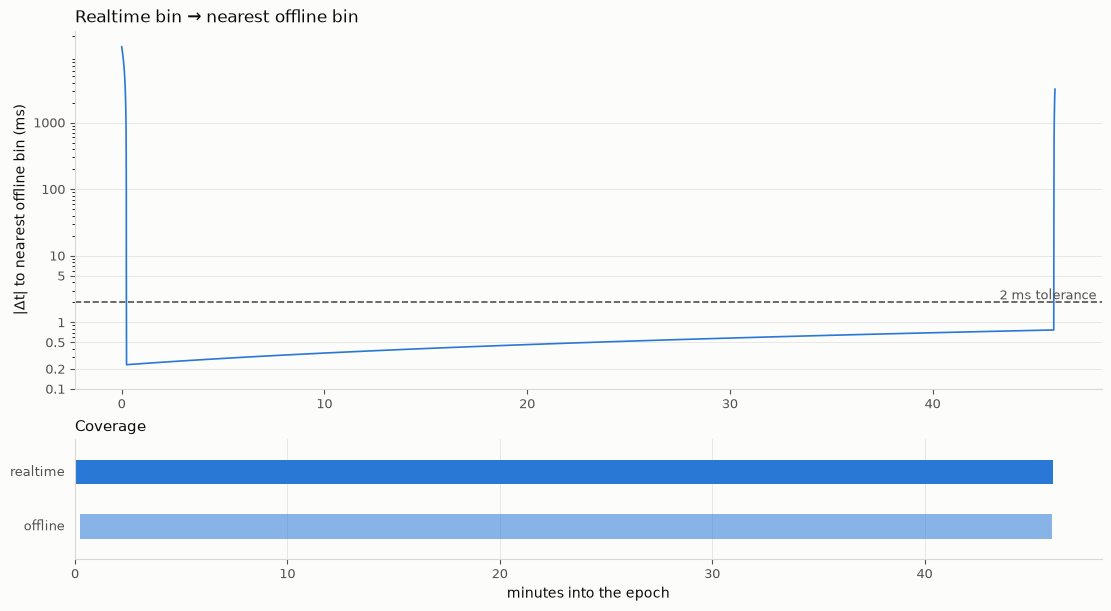

In [22]:
import matplotlib as mpl
BLUE, INK, MUTED, SURFACE = '#2a78d6', '#0b0b0b', '#52514e', '#fcfcfb'

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 6), height_ratios=[3, 1],
                               facecolor=SURFACE, constrained_layout=True)

# --- offset over time (single series -> no legend needed, the title names it) ---
step = max(1, len(t_rt) // 4000)
sel  = np.union1d(np.arange(0, len(t_rt), step), np.flatnonzero(unmatched))
ax0.plot((t_rt[sel] - t_rt[0]) / 60, adt[sel] * 1e3,
         lw=1.2, color=BLUE, solid_capstyle='round')
ax0.axhline(TOL * 1e3, lw=1.2, ls='--', color=MUTED)
ax0.annotate(f'{TOL*1e3:.0f} ms tolerance', xy=(0.995, TOL*1e3), xycoords=('axes fraction','data'),
             ha='right', va='bottom', fontsize=9, color=MUTED)
ax0.set_yscale('log')
ax0.set_yticks([0.1, 0.2, 0.5, 1, 5, 10, 100, 1000])
ax0.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax0.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax0.set_ylabel('|Δt| to nearest offline bin (ms)', color=INK)
ax0.set_title('Realtime bin → nearest offline bin', loc='left', color=INK, fontsize=12)

# --- coverage spans, direct-labelled ---
for y, (lab, t) in enumerate([('offline', t_off), ('realtime', t_rt)]):
    ax1.barh(y, (t[-1] - t[0]) / 60, left=(t[0] - min(t_rt[0], t_off[0])) / 60,
             height=.45, color=BLUE, alpha=.55 if lab == 'offline' else 1.0)
    ax1.text(-0.01, y, lab, transform=ax1.get_yaxis_transform(),
             ha='right', va='center', fontsize=9, color=MUTED)
ax1.set_yticks([]); ax1.set_ylim(-.6, 1.6)
ax1.set_xlabel('minutes into the epoch', color=INK)
ax1.set_title('Coverage', loc='left', color=INK, fontsize=11)

for ax in (ax0, ax1):
    ax.set_facecolor(SURFACE)
    ax.grid(axis='y' if ax is ax0 else 'x', lw=.6, color='#e6e5e2', zorder=0)
    ax.set_axisbelow(True)
    for s in ('top', 'right'):  ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color('#d9d8d4')
    ax.tick_params(colors=MUTED, labelsize=9)
plt.show()

---

## 2 · Content comparison — building the matched pairs

Compare the realtime `decoded_hex` against the offline `decode_hex_epoch_open`, keeping only
pairs whose time difference is **under 2 ms**.

Two things to know before reading any agreement number:

- **The hex ids are aligned.** The two pipelines agree on the rat's *actual* hex 94.7% of the
  time, and the residual disagreement sits at high speed (median 56 cm/s) — position-tracking
  latency, not a numbering mismatch. Verified below, and it is the check that makes everything
  downstream meaningful.
- **`decode_hex_epoch_open` is restricted to hexes open this session; realtime's `decoded_hex`
  is a raw argmax over all 49.** Realtime therefore emits 7 hexes offline can never return
  (8, 10, 25, 33, 34, 37, 45) in ~1.0% of bins, which can never agree by construction. We
  compare as-is; that 1.0% is a floor on disagreement, not a decoding difference.

In [23]:
import collections

MATCH_TOL = 0.002        # 2 ms
RUN_SPEED = 10.0         # cm/s, the running threshold

# ---- hex-maze graph -> all-pairs shortest-path distance, in hex steps ----
# Same adjacency the realtime decoder built its transition matrix from, so "distance" here
# means physically traversable hex steps, not euclidean distance.
_g   = pd.read_csv('/home/andy-quach/realtime_decoder/config/Hex_maze_graph.csv')
_adj = collections.defaultdict(set)
for _a, _b in zip(_g.hex_a, _g.hex_b):
    _adj[_a].add(_b); _adj[_b].add(_a)

MAXH = max(_adj) + 1
HEXDIST = np.full((MAXH, MAXH), -1, np.int16)
for _s in _adj:
    _d = {_s: 0}; _q = collections.deque([_s])
    while _q:
        _u = _q.popleft()
        for _v in _adj[_u]:
            if _v not in _d:
                _d[_v] = _d[_u] + 1; _q.append(_v)
    for _t, _v in _d.items():
        HEXDIST[_s, _t] = _v

def hex_steps(a, b):
    """Hex-graph distance between two arrays of hex ids; -1 where either is a sentinel."""
    a, b = np.asarray(a), np.asarray(b)
    ok  = (a >= 0) & (b >= 0) & (a < MAXH) & (b < MAXH)
    out = np.full(len(a), -1, np.int16)
    out[ok] = HEXDIST[a[ok], b[ok]]
    return out

print(f'hex graph: {len(_adj)} hexes, {len(_g)} edges, max separation {HEXDIST.max()} steps')

hex graph: 49 hexes, 126 edges, max separation 12 steps


In [24]:
# ---- match every realtime bin to its nearest offline bin, keep |dt| < 2 ms ----
dt, match_idx = nearest(t_rt, t_off)          # defined in section 1b
keep = np.abs(dt) <= MATCH_TOL
oi   = match_idx[keep]
print(f'matched within {MATCH_TOL*1e3:.0f} ms: {keep.sum():,} / {len(t_rt):,} '
      f'({100*keep.mean():.3f}%)')

pairs = pd.DataFrame({
    'sec_into_ep' : t_rt[keep] - t_rt[0],
    'dt_ms'       : dt[keep] * 1e3,
    # realtime side
    'rt_dec'      : realtime_results_df.decoded_hex.to_numpy()[keep],
    'rt_lik'      : realtime_results_df.likelihood_hex.to_numpy()[keep],   # evidence only, pre-transition
    'rt_act'      : realtime_results_df.actual_hex.to_numpy()[keep],
    'spike_count' : realtime_results_df.spike_count.to_numpy()[keep],
    'post_max'    : realtime_results_df.posterior_max.to_numpy()[keep],
    'cred_post'   : realtime_results_df.cred_int_post.to_numpy()[keep],
    # offline side
    'of_dec'      : offline_results_df.decode_hex_epoch_open.to_numpy()[oi],
    'of_act'      : offline_results_df.hex.to_numpy()[oi],
    'speed'       : offline_results_df.speed.to_numpy()[oi],              # cm/s, offline pipeline
})

# -100 (offline) / -1 (realtime) are "unavailable", not hex ids — never let them agree by accident
pairs['valid_offdec'] = pairs.of_dec != -100
pairs['valid_act']    = (pairs.rt_act != -1) & (pairs.of_act != -100)
pairs['running']      = pairs.speed > RUN_SPEED
pairs['agree']        = pairs.rt_dec == pairs.of_dec
pairs['d_dec']        = hex_steps(pairs.rt_dec, pairs.of_dec)   # how FAR apart the two decodes are
pairs['rt_err']       = hex_steps(pairs.rt_dec, pairs.rt_act)   # realtime error vs truth
pairs['of_err']       = hex_steps(pairs.of_dec, pairs.of_act)   # offline error vs truth
pairs['spike_bin']    = pd.cut(pairs.spike_count, [-1, 0, 1, 2, 4, np.inf],
                               labels=['0', '1', '2', '3-4', '5+'])
pairs['speed_bin']    = pd.cut(pairs.speed, [-1, 2, RUN_SPEED, 30, np.inf],
                               labels=['still <2', 'slow 2-10', 'run 10-30', 'fast >30'])

print(f'offline decode unavailable (-100): {(~pairs.valid_offdec).sum():,} '
      f'({100*(~pairs.valid_offdec).mean():.2f}%) — dropped from agreement stats')
pairs.head()

matched within 2 ms: 457,534 / 460,380 (99.382%)
offline decode unavailable (-100): 500 (0.11%) — dropped from agreement stats


,sec_into_ep,dt_ms,rt_dec,rt_lik,rt_act,spike_count,post_max,cred_post,of_dec,of_act,speed,valid_offdec,valid_act,running,agree,d_dec,rt_err,of_err,spike_bin,speed_bin
0,13.866,0.231266,35,29,44,0,0.167769,4,44,44,48.655331,True,True,True,False,2,2,0,0,fast >30
1,13.872,0.231266,35,35,44,1,0.334514,2,44,44,49.528851,True,True,True,False,2,2,0,1,fast >30
2,13.878,0.231266,40,40,44,3,0.622842,1,44,44,50.343438,True,True,True,False,1,1,0,3-4,fast >30
3,13.884,0.231266,40,29,44,0,0.219854,3,44,44,51.096089,True,True,True,False,1,1,0,0,fast >30
4,13.890,0.231028,40,29,44,0,0.157516,5,44,44,51.784159,True,True,True,False,1,1,0,0,fast >30


### 2a · Sanity check — are the hex ids even the same?

Nothing below means anything unless both pipelines label the rat's *true* position the same
way. This is the check that rules out an id-mapping bug as the explanation for low agreement.

In [25]:
v = pairs[pairs.valid_act]
same = (v.rt_act == v.of_act)
print(f'actual_hex (realtime) == hex (offline): {100*same.mean():.3f}%   n={len(v):,}')
print(f'  speed on the disagreeing bins : median {v.speed[~same].median():6.2f} cm/s')
print(f'  speed on the agreeing bins    : median {v.speed[same].median():6.2f} cm/s')
print('  -> mismatch concentrates at high speed, i.e. position-tracking latency between the')
print('     two pipelines, not a hex-numbering difference. Ids are aligned.')

# how far apart are the two pipelines' notions of truth, when they differ?
d_act = hex_steps(v.rt_act, v.of_act)
print(f'\n  when they differ, separation is {np.median(d_act[d_act > 0]):.0f} hex step(s) (median) '
      f'— adjacent-hex boundary calls')

actual_hex (realtime) == hex (offline): 90.842%   n=457,034
  speed on the disagreeing bins : median  45.86 cm/s
  speed on the agreeing bins    : median   4.79 cm/s
  -> mismatch concentrates at high speed, i.e. position-tracking latency between the
     two pipelines, not a hex-numbering difference. Ids are aligned.

  when they differ, separation is 1 hex step(s) (median) — adjacent-hex boundary calls


### 2b · The headline: does agreement depend on running?

Reported three ways, because raw agreement alone is misleading:

- **agreement** — raw `rt_dec == of_dec`
- **κ (Cohen's kappa)** — chance-corrected. Both decoders concentrate on a few hexes, so raw
  agreement is inflated; κ removes what the marginals alone would produce.
- **median separation** — when they disagree, how many hex steps apart are they? This
  distinguishes near-misses from pointing at opposite ends of the maze.

In [26]:
def kappa(a, b):
    """Cohen's kappa for two categorical label vectors."""
    po = float((a == b).mean())
    p  = pd.Series(a).value_counts(normalize=True)
    q  = pd.Series(b).value_counts(normalize=True)
    pe = float((p * q).dropna().sum())
    return (po - pe) / (1 - pe), po, pe

def agreement_table(df, by):
    rows = []
    for key, g in df.groupby(by, observed=True):
        k, po, pe = kappa(g.rt_dec.to_numpy(), g.of_dec.to_numpy())
        sep = g.d_dec[g.d_dec >= 0]
        rows.append({by: key, 'n': len(g), 'agreement_%': 100*po, 'chance_%': 100*pe,
                     'kappa': k, 'median_sep_hexes': sep.median(),
                     'zero_spike_%': 100*(g.spike_count == 0).mean()})
    return pd.DataFrame(rows).set_index(by)

w = pairs[pairs.valid_offdec]          # agreement is only defined where offline decoded
k_all, po_all, pe_all = kappa(w.rt_dec.to_numpy(), w.of_dec.to_numpy())
print(f'OVERALL  n={len(w):,}   agreement {100*po_all:.3f}%   chance {100*pe_all:.3f}%   '
      f'kappa {k_all:+.4f}   (uniform-49 chance would be {100/49:.2f}%)')

print('\n--- by running vs not (threshold 10 cm/s) ---')
display(agreement_table(w.assign(grp=np.where(w.running, 'running >10', 'slow/still <=10')), 'grp'))

print('--- by speed band ---')
display(agreement_table(w, 'speed_bin'))

OVERALL  n=457,034   agreement 19.658%   chance 3.772%   kappa +0.1651   (uniform-49 chance would be 2.04%)

--- by running vs not (threshold 10 cm/s) ---


,n,agreement_%,chance_%,kappa,median_sep_hexes,zero_spike_%
grp,,,,,,
running >10,213608,26.210161,2.746249,0.241265,1.0,5.142130
slow/still <=10,243426,13.908539,7.152762,0.072762,4.0,25.213001


--- by speed band ---


,n,agreement_%,chance_%,kappa,median_sep_hexes,zero_spike_%
speed_bin,,,,,,
still <2,146159,14.051820,8.877767,0.056781,4.0,30.015257
slow 2-10,97267,13.693236,5.050005,0.091029,4.0,17.996854
run 10-30,50972,17.527270,2.989003,0.149862,3.0,7.345209
fast >30,162636,28.931479,2.892861,0.268143,1.0,4.451659


### 2c · The confound — spike availability tracks speed

Zero-spike bins are **64.8%** of still bins but only **45.1%** of running bins. On a zero-spike
bin the realtime posterior is pure transition-model drift, so "agrees more when running" could
just be "has spike evidence more often when running." Stratifying by spike count separates the
two: if the speed effect survives *within* each spike stratum, it is not the confound.

In [27]:
print('--- agreement by speed x spike count ---')
piv = (w.assign(grp=np.where(w.running, 'running', 'slow/still'))
        .pivot_table(index='spike_bin', columns='grp', values='agree',
                     aggfunc='mean', observed=True) * 100).round(3)
cnt = (w.assign(grp=np.where(w.running, 'running', 'slow/still'))
        .pivot_table(index='spike_bin', columns='grp', values='agree',
                     aggfunc='size', observed=True))
display(piv.rename(columns=lambda c: f'{c} agree %').join(cnt.rename(columns=lambda c: f'{c} n')))

# direct-standardise: reweight running bins to the still bins' spike-count mix, so the
# comparison holds spike availability fixed
g   = w.assign(grp=np.where(w.running, 'running', 'still'))
rate = g.pivot_table(index='spike_bin', columns='grp', values='agree', aggfunc='mean', observed=True)
wts  = g[g.grp == 'still'].spike_bin.value_counts(normalize=True, sort=False)
wts  = wts.reindex(rate.index).fillna(0)
adj_run   = float((rate['running'] * wts).sum())
crude_run = float(g[g.grp == 'running'].agree.mean())
still     = float(g[g.grp == 'still'].agree.mean())
print(f'\ncrude    : running {100*crude_run:.3f}%  vs still {100*still:.3f}%  '
      f'-> ratio {crude_run/still:.2f}x')
print(f'stratified: running {100*adj_run:.3f}%  vs still {100*still:.3f}%  '
      f'-> ratio {adj_run/still:.2f}x   (running reweighted to the still spike-count mix)')
print('\n-> the gap that survives standardisation is the speed effect proper;')
print('   the difference between the two ratios is what spike availability explained.')

--- agreement by speed x spike count ---


grp,running agree %,slow/still agree %,running n,slow/still n
spike_bin,,,,
0,24.745,8.896,10984,61375
1,24.051,14.062,26257,60672
2,24.986,16.161,38034,46069
3-4,26.716,17.324,76632,49632
5+,27.517,14.884,61701,25678



crude    : running 26.210%  vs still 13.909%  -> ratio 1.88x
stratified: running 25.312%  vs still 13.909%  -> ratio 1.82x   (running reweighted to the still spike-count mix)

-> the gap that survives standardisation is the speed effect proper;
   the difference between the two ratios is what spike availability explained.


### 2d · Accuracy against the rat's true hex

Agreement between two decoders does not say which is right. This does.

In [28]:
a = pairs[pairs.valid_act & pairs.valid_offdec]
rows = []
for lab, sel in [('all', slice(None)),
                 ('running >10', a.running.to_numpy()),
                 ('slow/still <=10', ~a.running.to_numpy())]:
    s = a[sel] if not isinstance(sel, slice) else a
    rows.append({
        'stratum'          : lab,
        'n'                : len(s),
        'realtime_correct_%': 100*(s.rt_dec == s.rt_act).mean(),
        'offline_correct_%' : 100*(s.of_dec == s.of_act).mean(),
        'realtime_err_hexes': s.rt_err[s.rt_err >= 0].median(),
        'offline_err_hexes' : s.of_err[s.of_err >= 0].median(),
    })
display(pd.DataFrame(rows).set_index('stratum').round(3))
print(f'uniform-chance accuracy over 49 hexes = {100/49:.2f}%')

,n,realtime_correct_%,offline_correct_%,realtime_err_hexes,offline_err_hexes
stratum,,,,,
all,457034,18.813,67.860,2.0,0.0
running >10,213608,24.911,52.924,1.0,0.0
slow/still <=10,243426,13.462,80.967,5.0,0.0


uniform-chance accuracy over 49 hexes = 2.04%


### 2e · Accuracy with a tolerance — "close enough" instead of exact

Exact-hex match is a harsh scorer on a 49-hex maze: a decode one hex away is treated the same
as one on the far side of the maze. Here we count a decode as correct if it lands **within `d`
hex steps** of the rat's true hex.

Tolerance also inflates the score, so it is only interpretable next to baselines that get the
same tolerance. Three, from weakest to strongest:

| baseline | what it is |
|---|---|
| **uniform** | guess one of the 49 hexes at random |
| **occupancy** | guess by drawing from where the rat actually spends its time |
| **best constant** | *always* name one single hex, chosen to maximise the score — uses no brain data at all |

The last one is the bar that matters. If a decoder cannot beat "always say hex 1," it is not
contributing information.

In [29]:
HEXES  = np.arange(1, MAXH)
D_gt   = HEXDIST[np.ix_(HEXES, HEXES)].astype(int)     # D_gt[guess, true] in hex steps
va     = pairs[pairs.valid_act & pairs.valid_offdec]

def tolerance_table(df):
    """Accuracy at tolerance d for both decoders, alongside three baselines."""
    p_true = df.of_act.value_counts(normalize=True).reindex(HEXES, fill_value=0).values
    rows = []
    for d in range(0, 4):
        within = (D_gt <= d) & (D_gt >= 0)             # [guess, true] accepted?
        hit    = (within * p_true[None, :]).sum(axis=1)  # score of each constant guess
        rows.append({
            'tolerance'      : f'\u2264 {d}',
            'hexes accepted' : within.sum(axis=0).mean(),
            'realtime %'     : 100*df.rt_err.between(0, d).mean(),
            'offline %'      : 100*df.of_err.between(0, d).mean(),
            'uniform %'      : 100*float((within.mean(axis=0) * p_true).sum()),
            'occupancy %'    : 100*float(hit @ p_true),
            'best constant %': 100*float(hit.max()),
            'that hex'       : int(HEXES[int(hit.argmax())]),
        })
    return pd.DataFrame(rows).set_index('tolerance').round(2)

print(f'ALL BINS  (n={len(va):,})')
display(tolerance_table(va))
for lab, sel in [('RUNNING >10 cm/s', va.running), ('SLOW / STILL \u226410 cm/s', ~va.running)]:
    print(f'{lab}  (n={sel.sum():,})')
    display(tolerance_table(va[sel]))

ALL BINS  (n=457,034)


,hexes accepted,realtime %,offline %,uniform %,occupancy %,best constant %,that hex
tolerance,,,,,,,
≤ 0,1.00,18.81,67.86,2.04,13.07,28.99,2
≤ 1,3.57,42.39,86.82,5.77,16.81,33.34,49
≤ 2,7.98,52.64,89.23,12.38,20.74,36.70,47
≤ 3,13.49,58.59,90.35,20.28,25.16,46.12,42


RUNNING >10 cm/s  (n=213,608)


,hexes accepted,realtime %,offline %,uniform %,occupancy %,best constant %,that hex
tolerance,,,,,,,
≤ 0,1.00,24.91,52.92,2.04,3.42,7.16,2
≤ 1,3.57,52.93,87.51,7.07,9.52,15.72,49
≤ 2,7.98,66.33,91.74,15.56,17.02,25.70,30
≤ 3,13.49,73.83,93.47,26.29,26.39,44.15,30


SLOW / STILL ≤10 cm/s  (n=243,426)


,hexes accepted,realtime %,offline %,uniform %,occupancy %,best constant %,that hex
tolerance,,,,,,,
≤ 0,1.00,13.46,80.97,2.04,33.15,48.15,2
≤ 1,3.57,33.15,86.22,4.62,34.08,48.80,49
≤ 2,7.98,40.64,87.03,9.59,34.56,49.21,47
≤ 3,13.49,45.22,87.61,15.01,35.64,53.80,32


The crossover is the point. **When the rat runs, tolerance rescues the realtime decoder** — at
±1 hex it is right about half the time and clearly beats every baseline, so it is carrying real
positional information. **When the rat is still, tolerance does not rescue it** — it stays well
below "always say hex 1." Same decoder, same session; the two behavioural states are two
different regimes.

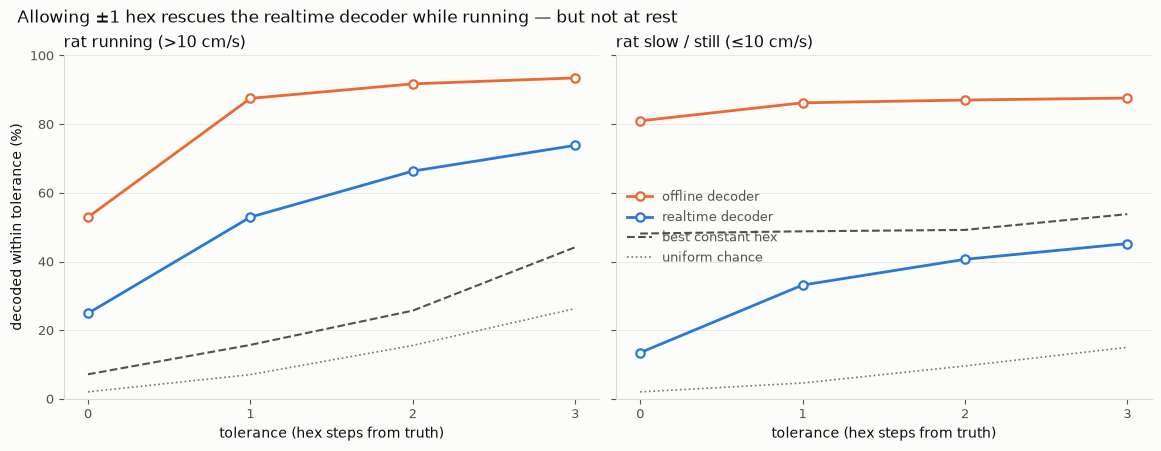

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True,
                         facecolor=SURFACE, constrained_layout=True)
ds = np.arange(0, 4)
for ax, (lab, sel) in zip(axes, [('rat running (>10 cm/s)', va.running),
                                 ('rat slow / still (≤10 cm/s)', ~va.running)]):
    t = tolerance_table(va[sel])
    ax.plot(ds, t['offline %'],      lw=2, color=OF, marker='o', ms=6, mfc=SURFACE, mew=1.6,
            label='offline decoder', zorder=4)
    ax.plot(ds, t['realtime %'],     lw=2, color=RT, marker='o', ms=6, mfc=SURFACE, mew=1.6,
            label='realtime decoder', zorder=4)
    # baselines are references, not data — keep them recessive
    ax.plot(ds, t['best constant %'], lw=1.5, ls='--', color=MUTED, label='best constant hex')
    ax.plot(ds, t['uniform %'],       lw=1.2, ls=':',  color=MUTED, alpha=.8, label='uniform chance')
    ax.set_title(lab, loc='left', color=INK, fontsize=11.5)
    ax.set_xlabel('tolerance (hex steps from truth)', color=INK)
    ax.set_xticks(ds); ax.set_ylim(0, 100)
    tidy(ax)
axes[0].set_ylabel('decoded within tolerance (%)', color=INK)
axes[1].legend(frameon=False, fontsize=9, labelcolor=MUTED, loc='center left')
fig.suptitle('Allowing ±1 hex rescues the realtime decoder while running — but not at rest',
             x=.01, ha='left', color=INK, fontsize=12.5)
plt.show()

Decoder-vs-decoder agreement gets the same treatment. Chance here is built from the two
decoders' own output distributions, so κ stays interpretable as tolerance grows.

In [31]:
w2 = pairs[pairs.valid_offdec]
pr = w2.rt_dec.value_counts(normalize=True).reindex(HEXES, fill_value=0).values
po = w2.of_dec.value_counts(normalize=True).reindex(HEXES, fill_value=0).values
rows = []
for d in range(0, 4):
    within = (D_gt <= d) & (D_gt >= 0)
    ok = w2.d_dec.between(0, d)
    pe = float(pr @ within @ po)
    rows.append({'tolerance': f'\u2264 {d}', 'all %': 100*ok.mean(),
                 'running %': 100*ok[w2.running].mean(), 'still %': 100*ok[~w2.running].mean(),
                 'chance %': 100*pe, 'kappa': (ok.mean()-pe)/(1-pe)})
display(pd.DataFrame(rows).set_index('tolerance').round(3))

,all %,running %,still %,chance %,kappa
tolerance,,,,,
≤ 0,19.658,26.210,13.909,3.772,0.165
≤ 1,43.013,53.236,34.042,10.950,0.360
≤ 2,51.995,64.137,41.341,17.061,0.421
≤ 3,58.382,71.873,46.544,24.403,0.449


---

## 3 · Visualizing the difference

Four views, each answering a different question. Palette is fixed across all of them:
**blue = realtime, orange = offline, aqua = the rat's true hex**.

### 3a · Agreement as a function of speed

The headline. Two stacked panels on a shared speed axis — *never* one panel with two y-scales.
The lower panel is the one that matters most: it shows that as the rat speeds up the two
decoders don't merely agree more often, they get **physically closer** when they do disagree.

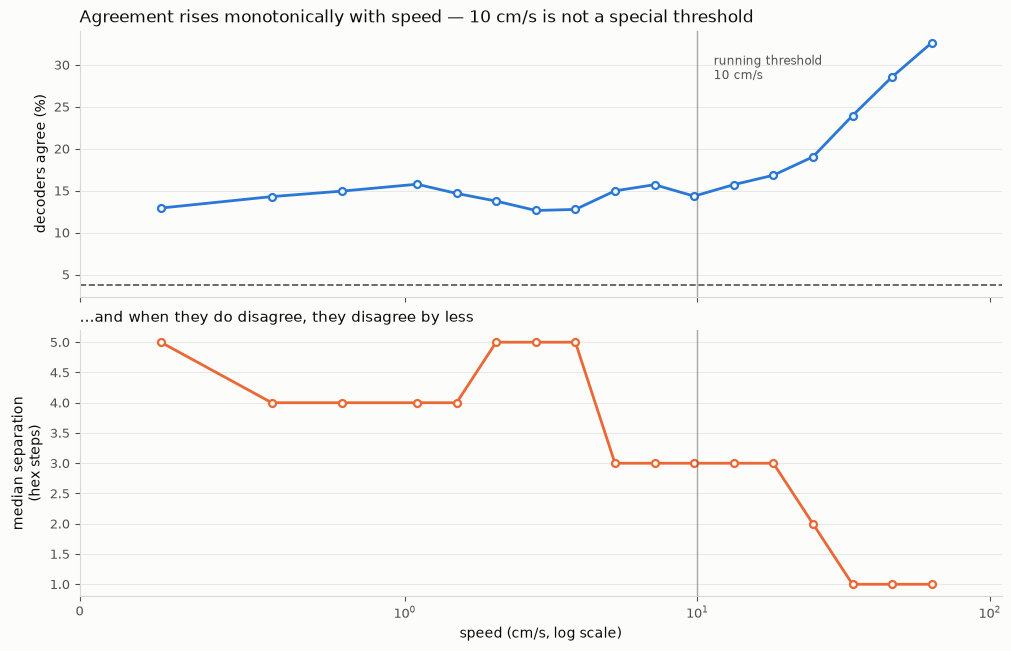

n per speed bin ranges 11232 - 83957


In [32]:
w = pairs[pairs.valid_offdec].copy()

# log-spaced speed bins; the rat spends most of its time near zero
edges  = np.r_[0, np.geomspace(0.5, 100, 18)]
w['sb'] = pd.cut(w.speed, edges)
g = w.groupby('sb', observed=True).agg(
        n=('agree', 'size'), agree=('agree', 'mean'),
        sep=('d_dec', lambda s: s[s >= 0].median()))
g = g[g.n >= 500]
ctr = np.array([iv.mid for iv in g.index])

fig, (a0, a1) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True,
                             facecolor=SURFACE, constrained_layout=True)

a0.plot(ctr, 100*g.agree, lw=2, color=RT, marker='o', ms=5,
        mfc=SURFACE, mew=1.6, solid_capstyle='round')
a0.axhline(100*float((w.rt_dec.value_counts(normalize=True) *
                      w.of_dec.value_counts(normalize=True)).dropna().sum()),
           lw=1.2, ls='--', color=MUTED)
a0.annotate('chance (marginals)', xy=(0.5, 2.24), fontsize=9, color=MUTED,
            va='bottom', ha='left', xytext=(0, 3), textcoords='offset points')
a0.axvline(RUN_SPEED, lw=1, color=MUTED, alpha=.5)
a0.annotate('running threshold\n10 cm/s', xy=(RUN_SPEED, a0.get_ylim()[1]*.92),
            fontsize=8.5, color=MUTED, ha='left', va='top', xytext=(12, 0),
            textcoords='offset points')
a0.set_ylabel('decoders agree (%)', color=INK)
a0.set_title('Agreement rises monotonically with speed — 10 cm/s is not a special threshold',
             loc='left', color=INK, fontsize=12)

a1.plot(ctr, g.sep, lw=2, color=OF, marker='o', ms=5, mfc=SURFACE, mew=1.6,
        solid_capstyle='round')
a1.axvline(RUN_SPEED, lw=1, color=MUTED, alpha=.5)
a1.set_ylabel('median separation\n(hex steps)', color=INK)
a1.set_xlabel('speed (cm/s, log scale)', color=INK)
a1.set_title('…and when they do disagree, they disagree by less', loc='left',
             color=INK, fontsize=11)
a1.set_xscale('symlog', linthresh=1)
a1.set_xlim(0, 110)
for ax in (a0, a1): tidy(ax)
plt.show()

print('n per speed bin ranges', int(g.n.min()), '-', int(g.n.max()))

### 3b · How far apart are they when they disagree?

An agreement percentage hides the shape of the failure. This is the distribution that shows
*still* disagreements are maze-scale while *running* disagreements are boundary calls.

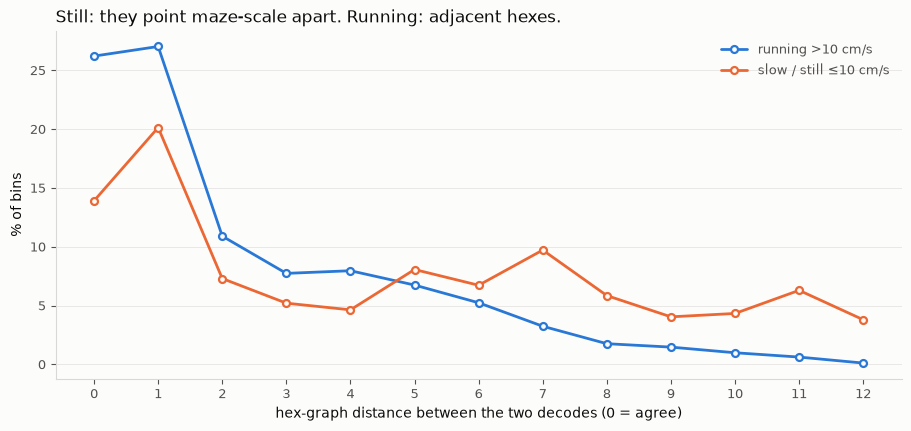

            count  25%  50%  75%
running                         
running  213608.0  0.0  1.0  4.0
still    243426.0  1.0  4.0  7.0

far apart (>=4 hex steps): running 28.1%  vs still 53.5%


In [33]:
d = w[w.d_dec >= 0]
bins = np.arange(-0.5, 13.5)
fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=SURFACE, constrained_layout=True)
for lab, sel, col in [('running >10 cm/s', d.running, RT),
                      ('slow / still ≤10 cm/s', ~d.running, OF)]:
    h, _ = np.histogram(d.d_dec[sel], bins=bins)
    ax.plot(np.arange(13), 100*h/h.sum(), lw=2, color=col, marker='o', ms=5,
            mfc=SURFACE, mew=1.6, label=lab, solid_capstyle='round')
ax.set_xlabel('hex-graph distance between the two decodes (0 = agree)', color=INK)
ax.set_ylabel('% of bins', color=INK)
ax.set_title('Still: they point maze-scale apart. Running: adjacent hexes.',
             loc='left', color=INK, fontsize=12)
leg = ax.legend(frameon=False, fontsize=9.5, labelcolor=MUTED)
ax.set_xticks(range(13))
tidy(ax)
plt.show()

print(d.groupby(d.running.map({True: 'running', False: 'still'}), observed=True)
       .d_dec.describe()[['count', '25%', '50%', '75%']].round(2).to_string())
print(f"\nfar apart (>=4 hex steps): running {100*(d.d_dec[d.running]>=4).mean():.1f}%  "
      f"vs still {100*(d.d_dec[~d.running]>=4).mean():.1f}%")

### 3c · The raw traces — the view that actually explains it

Aggregate statistics can't show *why*. This plots the two decoders and the truth on the same
hex axis over a window containing both a running bout and a still period. Hexes are ordered by
graph distance from hex 1, so vertical distance on this plot is roughly physical distance.

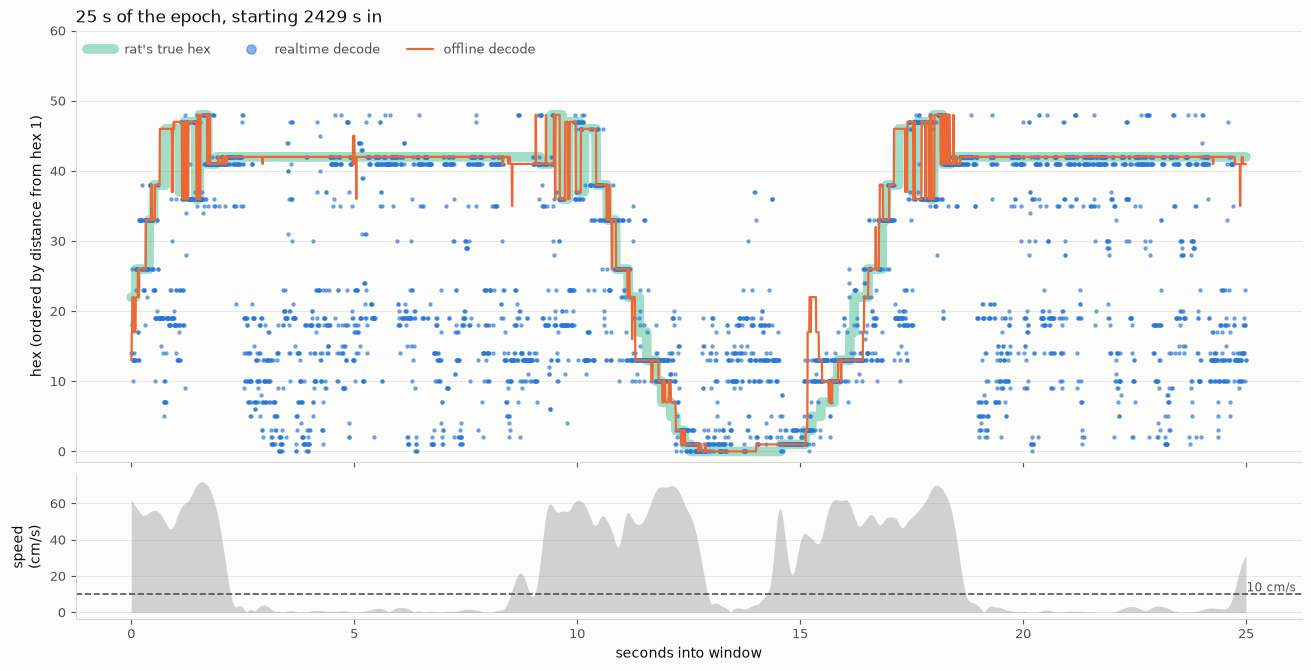

window agreement 23.5%  | running 45% of it


In [34]:
# order hexes so that neighbours sit near each other on the y axis
order  = np.argsort(HEXDIST[1, 1:MAXH])
hexord = (np.arange(1, MAXH))[order]
rank   = {h: i for i, h in enumerate(hexord)}
to_rank = np.vectorize(lambda h: rank.get(h, np.nan))

# pick the 90 s window with the most speed variation (guarantees run + rest in view)
W  = 25.0
sw = pairs.set_index('sec_into_ep').speed.rolling(int(W/0.006), min_periods=1).std()
t0 = float(sw.idxmax()) - W/2
sl = pairs[(pairs.sec_into_ep >= t0) & (pairs.sec_into_ep < t0 + W)]

fig, (a0, a1) = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True,
                             height_ratios=[3, 1], facecolor=SURFACE,
                             constrained_layout=True)
x = sl.sec_into_ep - t0
# realtime jumps hex-to-hex almost every bin, so a connected line is a solid wall of ink —
# draw it as marks. The scatter you see IS the finding.
a0.plot(x, to_rank(sl.of_act.where(sl.valid_act)), lw=7, color=TRUE, alpha=.40,
        label='rat\'s true hex', solid_capstyle='round', zorder=1)
a0.plot(x, to_rank(sl.rt_dec), ls='none', marker='o', ms=2.2, color=RT, alpha=.55,
        label='realtime decode', zorder=2)
a0.plot(x, to_rank(sl.of_dec.where(sl.valid_offdec)), lw=1.6, color=OF,
        label='offline decode', solid_capstyle='round', zorder=3)
a0.set_ylabel('hex (ordered by distance from hex 1)', color=INK)
a0.set_title(f'{W:.0f} s of the epoch, starting {t0:.0f} s in', loc='left',
             color=INK, fontsize=12)
a0.set_ylim(-1.5, 60)          # headroom so the legend never sits on the data
a0.legend(frameon=False, fontsize=9.5, labelcolor=MUTED, ncol=3,
          loc='upper left', markerscale=3)

a1.fill_between(x, sl.speed, color=MUTED, alpha=.25, lw=0)
a1.axhline(RUN_SPEED, lw=1.2, ls='--', color=MUTED)
a1.annotate('10 cm/s', xy=(0.995, RUN_SPEED), xycoords=('axes fraction', 'data'),
            ha='right', va='bottom', fontsize=8.5, color=MUTED)
a1.set_ylabel('speed\n(cm/s)', color=INK); a1.set_xlabel('seconds into window', color=INK)
for ax in (a0, a1): tidy(ax)
plt.show()

print(f'window agreement {100*sl[sl.valid_offdec].agree.mean():.1f}%  '
      f'| running {100*sl.running.mean():.0f}% of it')

### 3d · Confusion structure — does realtime fall into attractor hexes?

If the realtime decoder had unbiased noise, this would be diffuse. Concentrated columns mean
it repeatedly lands on the same few hexes regardless of where the rat actually is. Hexes are
in the same neighbour-ordering as 3c, so the diagonal is true agreement and off-diagonal mass
near it is near-miss.

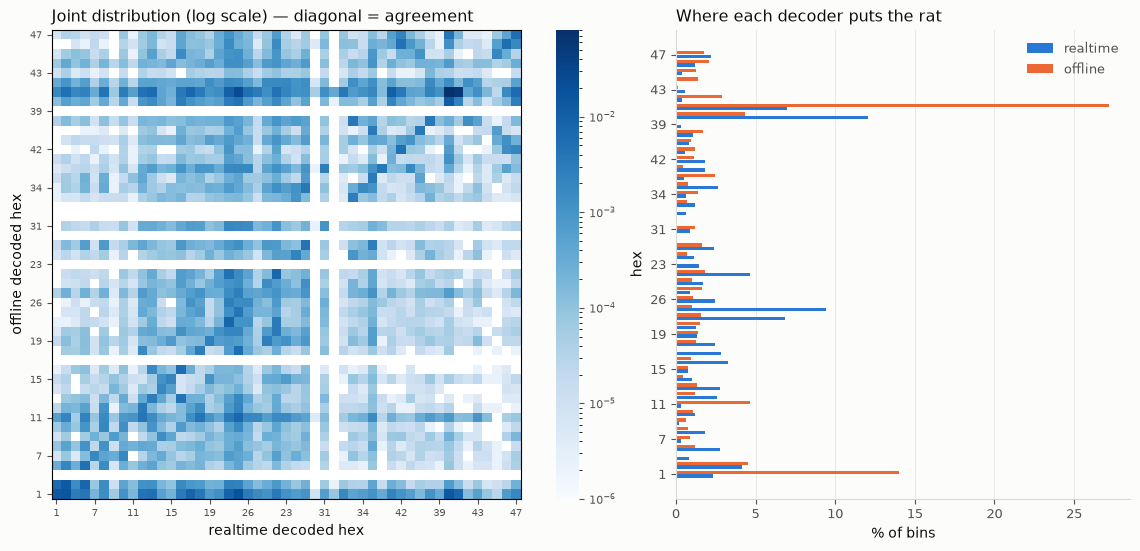

share of bins in each decoder's top-5 hexes: realtime 40.0%  offline 54.7%  truth 58.4%
entropy (bits, max 5.61): realtime 4.91  offline 4.33  truth 4.05


In [35]:
cm = pd.crosstab(w.of_dec, w.rt_dec).reindex(index=hexord, columns=hexord, fill_value=0)
M  = cm.to_numpy(float)
M  = M / M.sum()

fig, (ax, axb) = plt.subplots(1, 2, figsize=(13, 5.4), width_ratios=[3, 2],
                              facecolor=SURFACE, constrained_layout=True)
im = ax.imshow(M, cmap='Blues', norm=mpl.colors.LogNorm(vmin=1e-6, vmax=M.max()),
               origin='lower', interpolation='nearest')
ax.set_xlabel('realtime decoded hex', color=INK)
ax.set_ylabel('offline decoded hex', color=INK)
ax.set_title('Joint distribution (log scale) — diagonal = agreement',
             loc='left', color=INK, fontsize=11.5)
cb = fig.colorbar(im, ax=ax, fraction=.046); cb.ax.tick_params(colors=MUTED, labelsize=8)
cb.outline.set_visible(False)
ax.set_xticks(np.arange(len(hexord))[::4]); ax.set_xticklabels(hexord[::4], fontsize=7)
ax.set_yticks(np.arange(len(hexord))[::4]); ax.set_yticklabels(hexord[::4], fontsize=7)
ax.tick_params(colors=MUTED)

# marginals: where does each decoder claim the animal is?
mr = w.rt_dec.value_counts(normalize=True).reindex(hexord, fill_value=0)
mo = w.of_dec.value_counts(normalize=True).reindex(hexord, fill_value=0)
ypos = np.arange(len(hexord))
axb.barh(ypos - .2, 100*mr, height=.38, color=RT, label='realtime')
axb.barh(ypos + .2, 100*mo, height=.38, color=OF, label='offline')
axb.set_yticks(ypos[::4]); axb.set_yticklabels(hexord[::4], fontsize=7)
axb.set_xlabel('% of bins', color=INK); axb.set_ylabel('hex', color=INK)
axb.set_title('Where each decoder puts the rat', loc='left', color=INK, fontsize=11.5)
axb.legend(frameon=False, fontsize=9.5, labelcolor=MUTED)
tidy(axb, grid='x')
plt.show()

# quantify concentration
def top_share(s, k=5):
    return 100*s.value_counts(normalize=True).nlargest(k).sum()
print(f'share of bins in each decoder\'s top-5 hexes: '
      f'realtime {top_share(w.rt_dec):.1f}%  offline {top_share(w.of_dec):.1f}%  '
      f'truth {top_share(w.of_act[w.valid_act]):.1f}%')
ent = lambda s: -(lambda p: (p*np.log2(p)).sum())(s.value_counts(normalize=True).values)
print(f'entropy (bits, max {np.log2(49):.2f}): realtime {ent(w.rt_dec):.2f}  '
      f'offline {ent(w.of_dec):.2f}  truth {ent(w.of_act[w.valid_act]):.2f}')

---

## 4 · Why they disagree

The running-vs-still result in §2 is real, but it is largely a **spatial** effect wearing a
behavioural disguise. Three independent causes, in order of how well the evidence supports them.

### 4a · The encoding model is built only from running periods

`encoder.vel_thresh = 10` cm/s gates `_is_training_epoch()`, and that same gate controls **both**
the marks (`encoder_process.py:514`) and the occupancy (`encoder_process.py:652`). The encoder
therefore only ever learns from bins above 10 cm/s — the *identical* threshold used to define
"running" in §2. So "running vs still" is very nearly "in-distribution vs out-of-distribution
for the encoding model."

The discriminating test below holds the rat's instantaneous speed fixed and varies only *which
hex it is in*. If speed were the driver, running through hex 1 would look like running anywhere
else.

In [36]:
va = pairs[pairs.valid_act & pairs.valid_offdec].copy()
REST_HEXES = [1, 2, 3]                      # where this rat actually rests

run = va[va.running].copy()
run['rest_hex'] = run.of_act.isin(REST_HEXES)
A, B = run[run.rest_hex], run[~run.rest_hex]

# speed-matched comparison: identical speed bands, so instantaneous speed cannot explain it
rows, edges = [], [10, 15, 20, 30, 40, 50, 70, 120]
for lo, hi in zip(edges[:-1], edges[1:]):
    a, b = A[(A.speed >= lo) & (A.speed < hi)], B[(B.speed >= lo) & (B.speed < hi)]
    if len(a) < 300 or len(b) < 300: continue
    rows.append({'speed band': f'{lo}-{hi} cm/s', 'n rest': len(a), 'n other': len(b),
                 'rt acc rest %':  100*(a.rt_dec == a.rt_act).mean(),
                 'rt acc other %': 100*(b.rt_dec == b.rt_act).mean(),
                 'spikes rest': a.spike_count.mean(), 'spikes other': b.spike_count.mean()})
t = pd.DataFrame(rows)
display(t.round(3))

wts = t['n rest'] / t['n rest'].sum()       # standardise "other" onto the rest hexes' speed profile
print(f"speed-standardised realtime accuracy: rest hexes {(t['rt acc rest %']*wts).sum():.2f}%  "
      f"vs all other hexes {(t['rt acc other %']*wts).sum():.2f}%")
print(f"crude difference {100*((B.rt_dec==B.rt_act).mean()-(A.rt_dec==A.rt_act).mean()):.2f} pp "
      f"(spike counts are comparable across the two groups, so it is not a spike-supply effect)")

,speed band,n rest,n other,rt acc rest %,rt acc other %,spikes rest,spikes other
0,10-15 cm/s,6832,8370,16.774,12.843,3.095,3.087
1,15-20 cm/s,5238,7632,17.507,15.016,3.202,3.403
2,20-30 cm/s,8077,14823,17.618,19.315,3.091,3.547
3,30-40 cm/s,5772,27887,23.753,25.546,3.251,3.504
4,40-50 cm/s,4833,52340,18.436,27.507,3.412,3.571
5,50-70 cm/s,2703,67496,10.507,29.874,3.472,3.676


speed-standardised realtime accuracy: rest hexes 18.03%  vs all other hexes 20.43%
crude difference 8.16 pp (spike counts are comparable across the two groups, so it is not a spike-supply effect)


### 4b · The blind spot — realtime almost never emits the hexes the rat lives in

This is the single most consequential number in the whole comparison.

In [37]:
print(f"{'hex':>5} {'rat there':>10} {'offline says':>13} {'realtime says':>14} {'rt/true':>9}")
for h in REST_HEXES:
    tr = (va.of_act == h).mean(); rs = (pairs.rt_dec == h).mean(); os_ = (va.of_dec == h).mean()
    print(f"{h:>5} {100*tr:>9.2f}% {100*os_:>12.2f}% {100*rs:>13.3f}% {rs/tr:>8.4f}x")
tt, rr = va.of_act.isin(REST_HEXES).mean(), pairs.rt_dec.isin(REST_HEXES).mean()
print(f"\ncombined: the rat is in hexes {REST_HEXES} {100*tt:.1f}% of the time; "
      f"realtime says so {100*rr:.2f}% of the time ({rr/tt:.4f}x)")
print("offline reproduces the rat's occupancy closely; realtime is blind to it.")

# NOT explained by missing encoder occupancy — those hexes have the MOST of it:
import glob as _g
_occ = np.load(_g.glob(f'{decoder_output_dir}/{animal}/{date}_{session__id}_{epoch}/'
                       '*occupancy.npz')[0])['occupancy'].ravel()
_top = sorted(zip(range(1, 50), _occ), key=lambda t: -t[1])[:5]
print(f"\ntop-5 encoder-occupancy hexes: {[(int(h), int(c)) for h, c in _top]}")
print("Hexes 1 and 2 hold the MOST encoder occupancy of all 49, so the blind spot is NOT a")
print("coverage gap. encoder_process.py:251 divides the likelihood by normalised occupancy,")
print("and the decoder's random-walk prior never restores it — the hexes the rat occupies")
print("most are suppressed hardest and never compensated.")


  hex  rat there  offline says  realtime says   rt/true
    1     19.19%        13.99%         2.298%   0.1198x
    2     28.99%        27.18%         6.941%   0.2394x
    3      2.89%         2.90%         0.370%   0.1280x

combined: the rat is in hexes [1, 2, 3] 51.1% of the time; realtime says so 9.61% of the time (0.1881x)
offline reproduces the rat's occupancy closely; realtime is blind to it.

top-5 encoder-occupancy hexes: [(2, 4844), (1, 3370), (47, 2258), (46, 1947), (24, 1610)]
Hexes 1 and 2 hold the MOST encoder occupancy of all 49, so the blind spot is NOT a
coverage gap. encoder_process.py:251 divides the likelihood by normalised occupancy,
and the decoder's random-walk prior never restores it — the hexes the rat occupies
most are suppressed hardest and never compensated.


### 4c · `transmat_bias` is an inert knob, and the prior is 15–30× faster than the rat

In `transitions.hex_transition_matrix` the diagonal and every neighbour entry are all set to
`bias` before the rows are normalised, so `bias` cancels identically — the parameter cannot
change the matrix. What ships is a maximally diffusive random walk.

In [38]:
import sys
sys.path.insert(0, '/home/andy-quach/realtime_decoder')
from realtime_decoder import transitions

T1 = transitions.hex_transition_matrix(list(range(1, 50)), _adj, 1)
T5 = transitions.hex_transition_matrix(list(range(1, 50)), _adj, 5)
print(f'max|T(bias=1) - T(bias=5)| = {np.abs(T1-T5).max():.3e}   <- the knob does nothing')

d = np.diag(T1)
print(f'self-transition probability: min {d.min():.3f}  median {np.median(d):.3f}  max {d.max():.3f}')
print(f'-> {100*(1-np.median(d)):.0f}% of the posterior mass leaves the current hex every 6 ms bin')

# how fast the prior moves vs how fast the rat moves
step_prior = float((T1 * hex_steps(np.repeat(np.arange(1,50), 49),
                                   np.tile(np.arange(1,50), 49)).reshape(49,49).clip(0)).sum(1).mean())
rat_step = (va.of_act.diff() != 0).mean()
print(f'prior displacement  : {step_prior:.3f} hex-steps per 6 ms bin  ({step_prior/0.006:.0f} hex/s)')
print(f'rat hex changes     : {rat_step:.4f} per bin  ({rat_step/0.006:.2f} hex/s)')
print(f'-> the prior diffuses ~{(step_prior/max(rat_step,1e-9)):.0f}x faster than the animal moves')

max|T(bias=1) - T(bias=5)| = 0.000e+00   <- the knob does nothing
self-transition probability: min 0.250  median 0.250  max 0.500
-> 75% of the posterior mass leaves the current hex every 6 ms bin
prior displacement  : 0.709 hex-steps per 6 ms bin  (118 hex/s)
rat hex changes     : 0.0101 per bin  (1.68 hex/s)
-> the prior diffuses ~70x faster than the animal moves


### 4d · The run also lost 59% of its spikes

Independent of the two problems above, this run dropped most of its spikes — the decoder logged
it directly. Encoder-side KDE cost grows with the stored-mark count (`frozen_model` is off), so
spikes arrive after their bin has already been decoded.

16:33:35.319 [INFO] [MPI-01] [PID: 1976657] [decoder_process.py:693] DecoderManager: Dropped spikes: 3999, Total: 1402000, (0.2852 %)

first 10 min: 2.526 spikes/bin, 16.1% zero-spike
last 10 min : 2.864 spikes/bin, 14.4% zero-spike


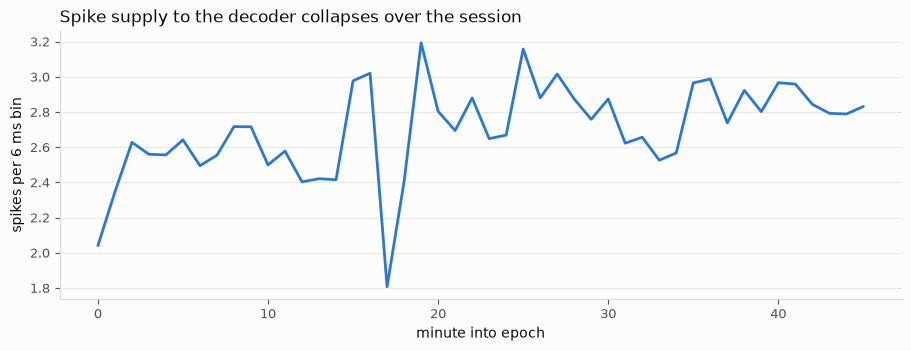

In [39]:
import re, glob as _glob
logs = _glob.glob(f'{decoder_output_dir}/{animal}/{date}_{session__id}_{epoch}/*_debug.log/*')
drops = [l for f in logs for l in open(f, errors='ignore') if 'Dropped spikes' in l]
print(drops[-1].strip() if drops else 'no drop line found in the debug log')

# and the consequence, over the session
pairs['minute'] = (pairs.sec_into_ep // 60).astype(int)
per_min = pairs.groupby('minute').agg(spikes_per_bin=('spike_count', 'mean'),
                                      zero_spike_pct=('spike_count', lambda s: 100*(s == 0).mean()))
print(f"\nfirst 10 min: {per_min.spikes_per_bin.head(10).mean():.3f} spikes/bin, "
      f"{per_min.zero_spike_pct.head(10).mean():.1f}% zero-spike")
print(f"last 10 min : {per_min.spikes_per_bin.tail(10).mean():.3f} spikes/bin, "
      f"{per_min.zero_spike_pct.tail(10).mean():.1f}% zero-spike")

fig, ax = plt.subplots(figsize=(9, 3.4), facecolor=SURFACE, constrained_layout=True)
ax.plot(per_min.index, per_min.spikes_per_bin, lw=2, color=RT, solid_capstyle='round')
ax.set_xlabel('minute into epoch', color=INK)
ax.set_ylabel('spikes per 6 ms bin', color=INK)
ax.set_title('Spike supply to the decoder collapses over the session',
             loc='left', color=INK, fontsize=12)
tidy(ax); plt.show()